# Граф ключевых слов научных публикаций

**Тема:** machine unlearning («разобучение» моделей).

Задача: убрать из обученной модели влияние части данных (объектов, класса, знаний), не переобучая её с нуля.
Нужно для «права на забвение» (GDPR), удаления опасных знаний из LLM и стирания понятий из генеративных моделей.

In [1]:
import os, re, time
import xml.etree.ElementTree as ET
from collections import Counter
from itertools import combinations

import matplotlib.pyplot as plt
import networkx as nx
import nltk
import numpy as np
import pandas as pd
import requests
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer

## 1–2. Сбор данных

Запрос к arXiv API: слово *unlearning* в названии или аннотации, ML-категории, статьи с 2020 года.
Берём 400 статей по 100 за запрос, пауза 3 секунды. Результат сохраняется в CSV.

In [2]:
CATS = ["cs.LG", "cs.AI", "cs.CL", "cs.CV", "cs.CR", "stat.ML"]
QUERY = ("(ti:unlearning OR abs:unlearning) AND (" + " OR ".join(f"cat:{c}" for c in CATS) + ")"
         " AND submittedDate:[202001010000 TO 202612312359]")
NS = {"a": "http://www.w3.org/2005/Atom", "arxiv": "http://arxiv.org/schemas/atom"}
DATA_FILE = "data/arxiv_unlearning.csv"


def fetch_arxiv(query, total=400, page=100):
    rows = []
    for start in range(0, total, page):
        params = {"search_query": query, "start": start, "max_results": page, "sortBy": "relevance"}
        for attempt in range(5):
            resp = requests.get("https://export.arxiv.org/api/query", params=params, timeout=60)
            entries = ET.fromstring(resp.content).findall("a:entry", NS)
            if entries:
                break
            time.sleep(5)
        for e in entries:
            rows.append({
                "id": e.find("a:id", NS).text.split("/abs/")[-1],
                "title": " ".join(e.find("a:title", NS).text.split()),
                "authors": "; ".join(a.find("a:name", NS).text for a in e.findall("a:author", NS)),
                "abstract": " ".join(e.find("a:summary", NS).text.split()),
                "published": e.find("a:published", NS).text[:10],
                "category": e.find("arxiv:primary_category", NS).attrib["term"],
            })
        print("скачано", len(rows))
        time.sleep(3)
    return pd.DataFrame(rows).drop_duplicates("id").reset_index(drop=True)


if os.path.exists(DATA_FILE):
    df = pd.read_csv(DATA_FILE)
else:
    os.makedirs("data", exist_ok=True)
    df = fetch_arxiv(QUERY)
    df.to_csv(DATA_FILE, index=False)

df["year"] = df["published"].str[:4].astype(int)
df = df[df["year"] >= 2020].reset_index(drop=True)
df["text"] = df["title"] + ". " + df["abstract"]
print("Статей:", len(df))
df[["title", "authors", "published", "category"]].head()

Статей: 399


,title,authors,published,category
0,Textual Unlearning Gives a False Sense of Unle...,Jiacheng Du; Zhibo Wang; Jie Zhang; Xiaoyi Pan...,2024-06-19,cs.CR
1,Meta-Unlearning on Diffusion Models: Preventin...,Hongcheng Gao; Tianyu Pang; Chao Du; Taihang H...,2024-10-16,cs.CV
2,SoK: Unlearnability and Unlearning for Model D...,Mengying Zhang; Derui Wang; Ruoxi Sun; Xiaoyu ...,2026-05-12,cs.LG
3,Unlearned but Not Forgotten: Data Extraction a...,Xiaoyu Wu; Yifei Pang; Terrance Liu; Zhiwei St...,2025-05-30,cs.LG
4,Machine Unlearning with Minimal Gradient Depen...,Tao Huang; Ziyang Chen; Jiayang Meng; Qingyu H...,2024-06-24,cs.LG


## 3. Разведочный анализ

**Нормализация:** нижний регистр -> убираем формулы -> *large language models* -> `llm` -> токены -> лемматизация ->
удаляем стоп-слова. Текст режем на фразы по знакам препинания и стоп-словам, чтобы n-граммы не склеивались
через границу фразы.

In [3]:
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
lemmatizer = WordNetLemmatizer()

STOP = set(stopwords.words("english")) | set('''
ability able achieve achieves across additionally address aim allow allows also among analysis analyze appear
approach art aspect available based best better can case certain challenge challenging code com common commonly
comprehensive conduct conducted consider considered could critical crucial current demonstrate despite different
due early effective effectively effectiveness empirical empirically enable enables end ensure ensuring evaluate
evaluated even existing experiment experimental explore explores exploring extensive fail find finding first focus
focuses framework further furthermore github given good help high highlight however http https illustrate important
importantly improve improvement improves including introduce investigate issue key know known large lead leading
less level leverage leverages leveraging light like little make makes making many may method might moreover much
multi must need needed new notably novel number observe occur often one open outperforms overall paper particular
particularly performance potential present previous prior problem promising propose proposed proposes provide range
real recent recently remains require requires result reveal scenario scenarios second set setting settings several
shed show shown significant significantly simple small specific specifically stage state still strong study suggest
superior task technique term terms tested theoretical theoretically three thus toward towards two type unique upon
us use used using various via view way well whether whose wide widely within without work world would yet
'''.split())

ACR_PLURAL = re.compile(r"^([a-z]*(?:lm|nn|gan|vae|mia|dm|vit))s$")
SPLIT_RE = re.compile(r"[.,;:!?()\[\]{}\"'/]|\s[-\u2013\u2014]\s")
WORD_RE = re.compile(r"[a-z0-9]+(?:-[a-z0-9]+)*")


def lemma(tok):
    return ACR_PLURAL.sub(r"\1", lemmatizer.lemmatize(tok))


def tokenize_raw(text):
    return re.findall(r"[a-z]+", text.lower())


def to_chunks(text):
    text = re.sub(r"\$[^$]*\$", " . ", text.lower())
    text = re.sub(r"\blarge language models?\b", " llm ", text)
    text = re.sub(r"\b(\w+)-to-(\w+)\b", r"\1 \2", text)
    chunks = []
    for part in SPLIT_RE.split(text):
        cur = []
        for word in WORD_RE.findall(part):
            for t in word.split("-"):
                t = lemma(t)
                if t in STOP or len(t) < 3 or not t.isalpha():
                    if cur:
                        chunks.append(cur)
                    cur = []
                else:
                    cur.append(t)
        if cur:
            chunks.append(cur)
    return chunks


def ngrams(chunks, n_max=3):
    out = []
    for ch in chunks:
        for n in range(1, n_max + 1):
            out += [" ".join(ch[i:i + n]) for i in range(len(ch) - n + 1)]
    return out


df["chunks"] = df["text"].apply(to_chunks)
df["tokens"] = df["chunks"].apply(lambda cs: [t for c in cs for t in c])
df["n_words"] = df["abstract"].apply(lambda s: len(tokenize_raw(s)))
df["n_authors"] = df["authors"].str.count(";") + 1
df[["n_words", "n_authors"]].describe().round(1)

,n_words,n_authors
count,399.0,399.0
mean,193.9,4.8
std,43.0,2.2
min,91.0,1.0
25%,162.5,3.0
50%,193.0,4.0
75%,225.0,6.0
max,299.0,19.0


year
2020      5
2021      8
2022     19
2023     33
2024    113
2025    146
2026     75

Самые активные авторы: [('Sijia Liu', 13), ('Tianqing Zhu', 10), ('Wanlei Zhou', 10), ('Yang Liu', 10), ('Jiali Cheng', 8)]


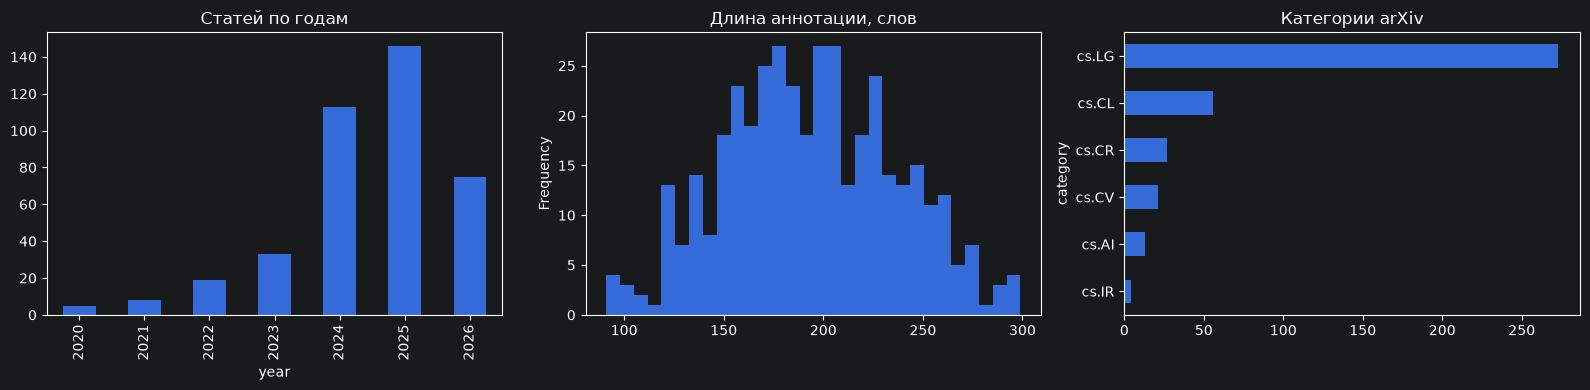

In [4]:
print(df["year"].value_counts().sort_index().to_string())
authors = Counter(a.strip() for s in df["authors"] for a in s.split(";"))
print("\nСамые активные авторы:", authors.most_common(5))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df["year"].value_counts().sort_index().plot.bar(ax=ax[0], title="Статей по годам")
df["n_words"].plot.hist(bins=30, ax=ax[1], title="Длина аннотации, слов")
df["category"].value_counts().head(6).plot.barh(ax=ax[2], title="Категории arXiv").invert_yaxis()
plt.tight_layout()
plt.show()

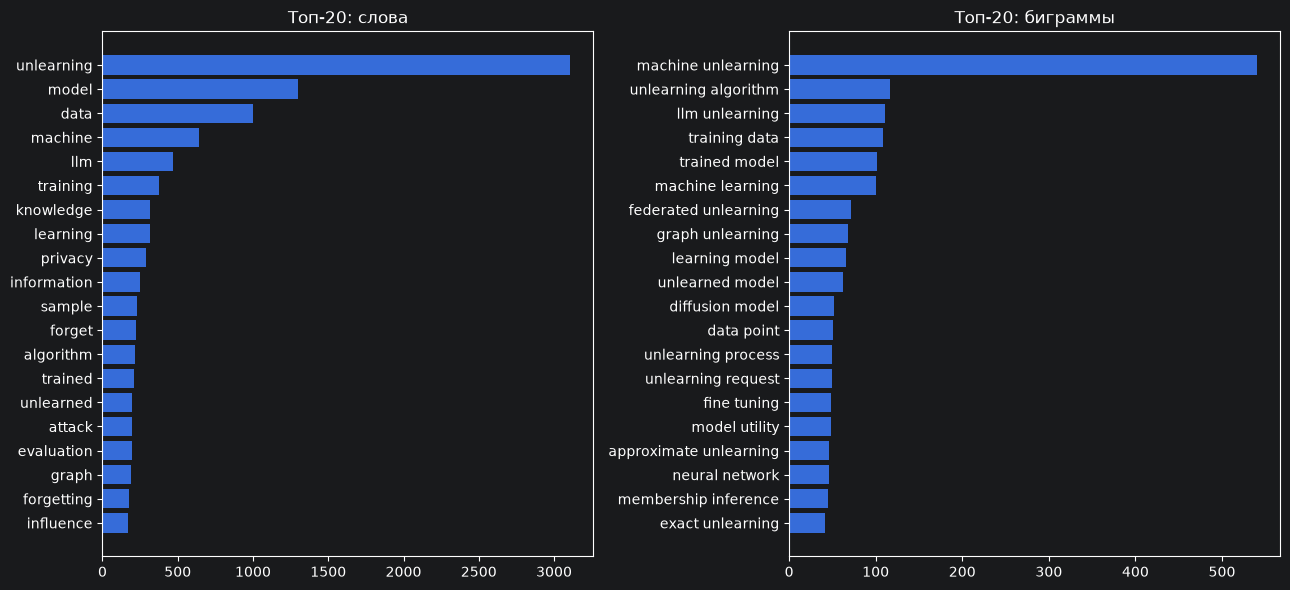

In [5]:
uni = Counter(t for toks in df["tokens"] for t in toks)
bi = Counter(g for cs in df["chunks"] for g in ngrams(cs) if g.count(" ") == 1)

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
for a, cnt, name in [(ax[0], uni, "слова"), (ax[1], bi, "биграммы")]:
    top = cnt.most_common(20)[::-1]
    a.barh([w for w, _ in top], [c for _, c in top])
    a.set_title(f"Топ-20: {name}")
plt.tight_layout()
plt.show()

### Закон Ципфа

Частота слова ≈ C / ранг, в log-log осях это прямая с наклоном −1. Берём «сырые» слова, без стоп-слов и лемматизации.

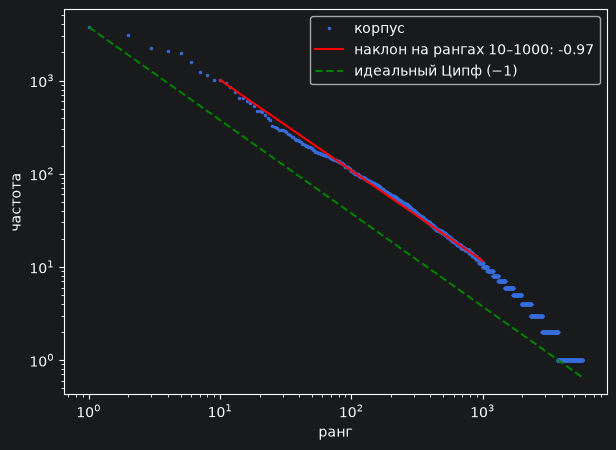

Словарь: 5713 слов, наклон по всем рангам: -1.27, на рангах 10–1000: -0.97


In [6]:
freqs = np.array(sorted(Counter(t for s in df["text"] for t in tokenize_raw(s)).values(), reverse=True))
ranks = np.arange(1, len(freqs) + 1)
mid = (ranks >= 10) & (ranks <= 1000)
s_all = np.polyfit(np.log(ranks), np.log(freqs), 1)[0]
s_mid, c_mid = np.polyfit(np.log(ranks[mid]), np.log(freqs[mid]), 1)

plt.figure(figsize=(7, 5))
plt.loglog(ranks, freqs, ".", ms=3, label="корпус")
plt.loglog(ranks[mid], np.exp(c_mid) * ranks[mid] ** s_mid, "r-", label=f"наклон на рангах 10–1000: {s_mid:.2f}")
plt.loglog(ranks, freqs[0] / ranks, "g--", label="идеальный Ципф (−1)")
plt.xlabel("ранг")
plt.ylabel("частота")
plt.legend()
plt.show()
print(f"Словарь: {len(freqs)} слов, наклон по всем рангам: {s_all:.2f}, на рангах 10–1000: {s_mid:.2f}")

**Итоги анализа:**
- 399 статей, 2020–2026. Рост с 2024 года (113 статей, в 2025 году 146), вместе с разобучением LLM.
- 68% статей из cs.LG, дальше cs.CL, cs.CR, cs.CV. В среднем 4.8 автора, аннотация ~194 слова.
- Частые биграммы сразу показывают подтемы: *llm unlearning, federated unlearning, graph unlearning, diffusion model*.
- Ципф выполняется: наклон −0.97 на средних рангах. По всем рангам −1.27: мешают самые частые слова и редкие слова в хвосте.

## 4. Ключевые слова

TF-IDF по 1–3-граммам. `min_df=3`: термин должен быть хотя бы в 3 статьях, `max_df=0.5`: убираем слова,
которые есть почти везде (*unlearning, model, data*). У каждой статьи берём 10 лучших терминов без повторов
(вместо *gradient* + *ascent* остаётся *gradient ascent*).

In [7]:
vectorizer = TfidfVectorizer(analyzer=ngrams, min_df=3, max_df=0.5)
X = vectorizer.fit_transform(df["chunks"])
vocab = vectorizer.get_feature_names_out()


def top_keywords(row, k=10):
    chosen = []
    for idx in row.indices[np.argsort(-row.data)]:
        term = vocab[idx]
        if any(f" {term} " in f" {c} " for c in chosen):
            continue
        chosen = [c for c in chosen if f" {c} " not in f" {term} "] + [term]
        if len(chosen) == k:
            break
    return chosen


df["keywords"] = [top_keywords(X[i]) for i in range(X.shape[0])]
kw_doc_freq = Counter(k for kws in df["keywords"] for k in kws)
print("Уникальных ключевых слов:", len(kw_doc_freq))
print("Самые частые:", kw_doc_freq.most_common(15))
df[["title", "keywords"]].head()

Уникальных ключевых слов: 1742
Самые частые: [('llm', 51), ('llm unlearning', 24), ('forget', 22), ('federated unlearning', 20), ('graph unlearning', 19), ('sample', 19), ('knowledge', 17), ('forgetting', 15), ('client', 15), ('retain', 15), ('gradient', 14), ('learning', 14), ('gnn', 13), ('user', 13), ('class', 12)]


,title,keywords
0,Textual Unlearning Gives a False Sense of Unle...,"[textual, unlearning mechanism, false sense, g..."
1,Meta-Unlearning on Diffusion Models: Preventin...,"[meta unlearning, concept, unlearned, finetuni..."
2,SoK: Unlearnability and Unlearning for Model D...,"[unlearnability, shallow, perturbation, learna..."
3,Unlearned but Not Forgotten: Data Extraction a...,"[extraction, unlearning model, post unlearning..."
4,Machine Unlearning with Minimal Gradient Depen...,"[ratio, gradient, historical, mapping, minimal..."


## 5. Граф ключевых слов

Вершины: ключевые слова (из ≥3 статей). Ребро: слова встретились в одной статье. Вес: число таких статей.

In [8]:
G = nx.Graph()
for kws in df["keywords"]:
    kws = [k for k in kws if kw_doc_freq[k] >= 3]
    for a, b in combinations(sorted(kws), 2):
        w = G[a][b]["weight"] + 1 if G.has_edge(a, b) else 1
        G.add_edge(a, b, weight=w)
G = G.subgraph(max(nx.connected_components(G), key=len)).copy()
for a, b, d in G.edges(data=True):
    d["distance"] = 1 / d["weight"]

print(f"{G.number_of_nodes()} вершин, {G.number_of_edges()} рёбер")
for a, b, d in sorted(G.edges(data=True), key=lambda e: -e[2]["weight"])[:5]:
    print(f"  {a} - {b}: {d['weight']}")

460 вершин, 5077 рёбер
  client — federated unlearning: 11
  graph unlearning — gnn: 9
  graph unlearning — node: 8
  knowledge — llm: 6
  client — server: 6


## 6. Кластеры

Алгоритм Louvain, качество оцениваем модулярностью Q (чем больше, тем лучше разделены кластеры; 0 значит как случайно).

In [9]:
communities = sorted(nx.community.louvain_communities(G, weight="weight", seed=42), key=len, reverse=True)
print(f"Кластеров: {len(communities)}, модулярность Q = {nx.community.modularity(G, communities, weight='weight'):.2f}\n")
for i, com in enumerate(communities):
    sub = G.subgraph(com)
    best = sorted(com, key=lambda n: sub.degree(n, weight="weight"), reverse=True)[:10]
    print(f"{i} ({len(com)} слов): {', '.join(best)}")

Кластеров: 10, модулярность Q = 0.30

0 (88 слов): llm, knowledge, forgetting, representation, evaluation, utility, token, output, general, emph
1 (64 слов): sample, forget, retain, class, approximate unlearning, algorithm, space, degradation, accuracy, image
2 (51 слов): diffusion model, prompt, concept, language, quality, text, data unlearning, linguistic, resource, face
3 (50 слов): graph unlearning, node, gnn, unlearned, mia, unlearning algorithm, full, certified, edge, graph data
4 (48 слов): federated unlearning, client, server, global model, time, local, multiple, verifiable unlearning, influence, update
5 (48 слов): unlearnable example, training, subset, loss, adversarial training, gradient, perturbation, noise, unlearning process, unlearnability
6 (38 слов): example, llm unlearning, information, learning, model utility, adversarial, score, perspective, shard, safety
7 (31 слов): survey, system, application, user, domain, researcher, centralized, topic, neural network, provable

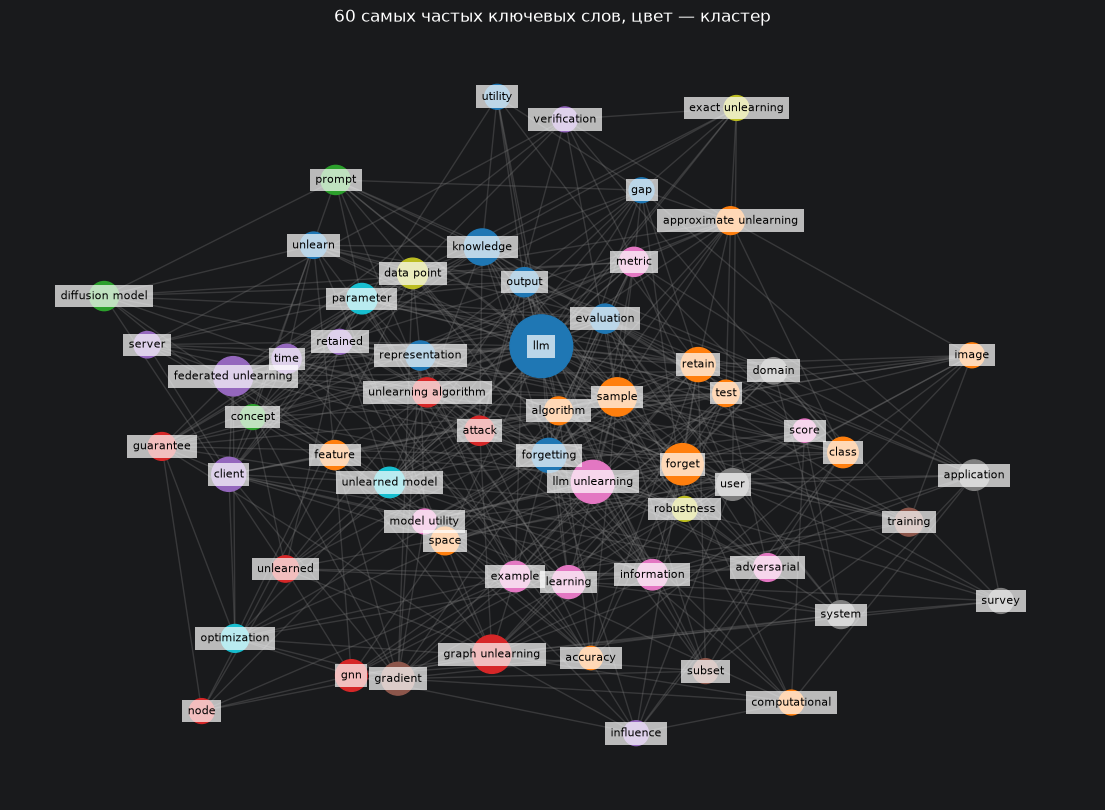

In [10]:
node_com = {n: i for i, c in enumerate(communities) for n in c}
H = G.subgraph(sorted(G.nodes, key=lambda n: kw_doc_freq[n], reverse=True)[:60])
pos = nx.spring_layout(H, weight="weight", seed=1, k=0.7)
plt.figure(figsize=(14, 10))
nx.draw_networkx_edges(H, pos, alpha=0.3, edge_color="gray")
nx.draw_networkx_nodes(H, pos, node_color=[node_com[n] for n in H], cmap="tab10",
                       node_size=[40 * kw_doc_freq[n] for n in H])
nx.draw_networkx_labels(H, pos, font_size=8, bbox=dict(fc="white", ec="none", alpha=0.7))
plt.title("60 самых частых ключевых слов, цвет: кластер")
plt.axis("off")
plt.show()

**Что получилось.** 10 кластеров, Q = 0.30: структура есть, но подтемы пересекаются: общие слова
(*forget, retain, sample*) и хаб *llm* встречаются во всех направлениях. Слова попадают в один кластер,
потому что часто стоят вместе в одних статьях:

| № | Слова | Направление |
|---|---|---|
| 0 | llm, knowledge, forgetting, evaluation, utility, token | разобучение LLM |
| 1 | sample, forget, retain, class, accuracy, image | забыть примеры или класс в классификаторе |
| 2 | diffusion model, prompt, concept, text, face | стирание понятий в генерации картинок |
| 3 | graph unlearning, node, gnn, edge, attack | разобучение графовых сетей и атаки на него |
| 4 | federated unlearning, client, server, global model | федеративное разобучение (удалить клиента) |
| 5 | unlearnable example, adversarial training, noise | «необучаемые» данные, защита от обучения |
| 6 | llm unlearning, safety, adversarial, shard | разобучение для безопасности |
| 7 | survey, system, application, user | обзоры |
| 8 | data point, weighted, fairness, exact unlearning | удаление отдельных объектов |
| 9 | mode connectivity, optimization, parameter | геометрия весов модели (2–3 статьи) |

Кластеры 0–5 понятные направления. 6–9 размытые, из-за них Q не выше.

## 7. Центральности

- **degree**: со сколькими словами связано слово;
- **betweenness**: насколько слово служит «мостом» между группами;
- **eigenvector**: связано ли слово с другими важными словами;
- **closeness**: как быстро от слова дойти до всех остальных.

In [11]:
centr = pd.DataFrame({
    "degree": nx.degree_centrality(G),
    "betweenness": nx.betweenness_centrality(G, weight="distance"),
    "eigenvector": nx.eigenvector_centrality(G, weight="weight", max_iter=2000),
    "closeness": nx.closeness_centrality(G, distance="distance"),
})
pd.DataFrame({c: centr[c].nlargest(10).index for c in centr})

,degree,betweenness,eigenvector,closeness
0,llm,llm,llm,llm
1,forget,knowledge,federated unlearning,knowledge
2,sample,forget,knowledge,forgetting
3,llm unlearning,sample,client,evaluation
4,knowledge,federated unlearning,forgetting,output
5,federated unlearning,llm unlearning,forget,utility
6,graph unlearning,graph unlearning,sample,token
7,forgetting,unlearned model,evaluation,query
8,retain,forgetting,unlearned model,forget
9,learning,prompt,graph unlearning,metric


**Что получилось.**
- **llm** на первом месте везде с большим отрывом: разобучение LLM главная подтема, и слово встречается во всех направлениях.
- **degree:** *forget, sample, retain*: базовые понятия любой статьи (что забыть, что сохранить) + названия подтем.
- **betweenness:** *knowledge, prompt, federated unlearning* связывают разные подтемы
  (например, *prompt* есть и в LLM, и в диффузионных моделях).
- **eigenvector:** выше обычного *federated unlearning, client*: в этом кластере самые сильные связи.
- **closeness:** почти все слова из кластера LLM, он в центре темы.

## 8. Граф публикаций и похожие статьи

Вершины: статьи. Ребро: есть общие ключевые слова. Вес: их количество.
Похожие статьи: соседи с наибольшим весом (при равенстве выше та, где общие слова реже).

In [12]:
kw_to_docs = {}
for i, kws in df["keywords"].items():
    for k in kws:
        kw_to_docs.setdefault(k, []).append(i)
idf = {k: np.log(len(df) / len(ids)) for k, ids in kw_to_docs.items()}

P = nx.Graph()
P.add_nodes_from(df.index)
for k, ids in kw_to_docs.items():
    for a, b in combinations(ids, 2):
        if P.has_edge(a, b):
            P[a][b]["weight"] += 1
            P[a][b]["idf"] += idf[k]
            P[a][b]["shared"].append(k)
        else:
            P.add_edge(a, b, weight=1, idf=idf[k], shared=[k])
print(f"{P.number_of_nodes()} статей, {P.number_of_edges()} рёбер")
print("Веса рёбер:", dict(sorted(Counter(d["weight"] for _, _, d in P.edges(data=True)).items())))


def similar_papers(i, k=5):
    print("Статья:", df.at[i, "title"])
    neigh = sorted(P[i].items(), key=lambda x: (x[1]["weight"], x[1]["idf"]), reverse=True)[:k]
    for j, d in neigh:
        print(f"  w={d['weight']}  {df.at[j, 'title'][:80]}  | общие: {d['shared']}")


similar_papers(1)

399 статей, 7189 рёбер
Веса рёбер: {1: 6608, 2: 523, 3: 48, 4: 8, 5: 1, 10: 1}
Статья: Meta-Unlearning on Diffusion Models: Preventing Relearning Unlearned Concepts
  w=2  Towards Irreversible Machine Unlearning for Diffusion Models  | общие: ['finetuning', 'diffusion model']
  w=2  TILDE: TILt-based Distributional Erasure for Concept Unlearning  | общие: ['diffusion model', 'benign']
  w=2  How to Protect Models against Adversarial Unlearning?  | общие: ['unlearned', 'malicious']
  w=2  Unlearning in Diffusion Models: A Unified Framework with KL Divergence and Likel  | общие: ['concept', 'diffusion model']
  w=2  Unlearning or Concealment? A Critical Analysis and Evaluation Metrics for Unlear  | общие: ['concept', 'diffusion model']


Почти все рёбра (92%) имеют вес 1: у статей обычно одно общее слово. Для статьи про Meta-Unlearning 4 из 5 соседей
с весом 2 тоже про диффузионные модели, т.е. поиск работает. Ребро с весом 10 означает дубликат одной статьи в данных.

## 9. Поиск по графу публикаций

1. Нормализуем запрос и ищем в нём ключевые слова графа.
2. Статьи с этими словами становятся стартовыми (редкое слово весит больше).
3. Personalized PageRank по графу поднимает статьи, связанные со стартовыми, даже без совпадения слов.

In [13]:
def search(query, k=5, verbose=True):
    chunks = to_chunks(query)
    grams = set(ngrams(chunks))
    matched = [kw for kw in kw_to_docs if kw in grams]
    matched = [kw for kw in matched if not any(kw != m and f" {kw} " in f" {m} " for m in matched)]
    seeds = Counter()
    for kw in matched:
        for i in kw_to_docs[kw]:
            seeds[i] += idf[kw]
    if not seeds:
        q = {t for c in chunks for t in c}
        seeds = Counter({i: len(q & set(t)) for i, t in df["tokens"].items() if q & set(t)})
    if not seeds:
        return []
    pr = nx.pagerank(P, alpha=0.5, personalization=dict(seeds), weight="weight")
    result = sorted(pr, key=pr.get, reverse=True)[:k]
    if verbose:
        print(f"'{query}' -> совпали: {matched}")
        for j in result:
            print(f"   {df.at[j, 'title'][:85]}" + ("" if j in seeds else "   [через граф]"))
    return result


tests = [
    "unlearning in large language models with gradient ascent",
    "concept erasure in text-to-image diffusion models",
    "federated unlearning of clients",
    "membership inference attack to verify unlearning",
    "graph neural network unlearning",
    "certified unlearning with influence functions",
]
for t in tests:
    search(t)

'unlearning in large language models with gradient ascent' -> совпали: ['llm', 'gradient ascent']
   A More Practical Approach to Machine Unlearning
   Large Language Model Unlearning via Embedding-Corrupted Prompts
   Understanding the Dilemma of Unlearning for Large Language Models
   Multilingual Unlearning in LLMs: Transfer, Dynamics, and Reversibility
   Align-then-Unlearn: Embedding Alignment for LLM Unlearning
'concept erasure in text-to-image diffusion models' -> совпали: ['concept', 'erasure', 'text image diffusion', 'image diffusion model']
   Holistic Unlearning Benchmark: A Multi-Faceted Evaluation for Text-to-Image Diffusion
   eval-unlearn: Benchmarking unlearning in Text-to-Image Diffusion Models
   TILDE: TILt-based Distributional Erasure for Concept Unlearning
   Challenging Forgets: Unveiling the Worst-Case Forget Sets in Machine Unlearning
   Meta-Unlearning on Diffusion Models: Preventing Relearning Unlearned Concepts
'federated unlearning of clients' -> совпали: ['

### Тестирование

- **P@5**: доля результатов, где есть хотя бы половина слов запроса (без общих *unlearning, model, machine, learning*).
- **Поиск по названию**: ищем 50 случайных статей по их названию, статья должна быть в топ-5.

In [14]:
GENERIC = {"unlearning", "model", "machine", "learning"}
for t in tests:
    q = {w for c in to_chunks(t) for w in c} - GENERIC
    rel = [len(q & set(df.at[j, "tokens"])) >= len(q) / 2 for j in search(t, verbose=False)]
    print(f"P@5 = {np.mean(rel):.1f}   {t}")

sample = df.sample(50, random_state=0)
hits = sum(i in search(r["title"], verbose=False) for i, r in sample.iterrows())
print(f"\nПоиск по названию: найдено в топ-5 {hits} из 50")

P@5 = 0.2   unlearning in large language models with gradient ascent
P@5 = 0.6   concept erasure in text-to-image diffusion models
P@5 = 1.0   federated unlearning of clients
P@5 = 0.4   membership inference attack to verify unlearning
P@5 = 1.0   graph neural network unlearning
P@5 = 0.4   certified unlearning with influence functions

Поиск по названию: найдено в топ-5 46 из 50


**Что получилось.**
- По федеративному, графовому и сертифицированному разобучению выдача по теме. Для GNN три статьи из пяти найдены
  через граф, без прямого совпадения слов.
- Ошибки: частое слово *llm* «забивает» выдачу (P@5 = 0.2), общее слово *verify* уводит в рекомендательные системы.
- Средний P@5 = 0.6, по названию статья находится в топ-5 в 46 из 50 случаев.

## Выводы

1. Собрано 399 статей arXiv по machine unlearning (2020–2026), бурный рост с 2024 года.
2. Закон Ципфа выполняется (наклон −0.97 на средних рангах).
3. Ключевые слова: TF-IDF по 1–3-граммам, 10 на статью. Есть шум (*give, ten, emph*), но основные термины выделены.
4. Граф ключевых слов делится на 10 кластеров (Q = 0.30): LLM, классификация, диффузионные модели, графы,
   федеративное обучение и т.д.
5. Самое центральное слово *llm*, мосты между подтемами *knowledge, prompt*.
6. Поиск по графу находит статьи по подтеме, в том числе без совпадения слов, но ошибается на частых и общих словах.